# Plastic Detection and Classification by Image Segmentation
## Micro- and Nanoplastics from Microscope Images

**Author:** Ramya

---

### Abstract

Micro- and nanoplastic pollution poses a significant environmental concern globally.
The diverse materials and morphologies of these plastics carry crucial information about
their toxicity across various biological levels. However, detecting and classifying these
particles in real-world scenarios is challenging due to their minute sizes and the
complexity of environmental samples.

This notebook develops a complete image segmentation pipeline capable of identifying and
classifying microplastics from the **DeepParticle** dataset of microscope images.  Four
state-of-the-art segmentation architectures (U-Net, U-Net++, DeepLabV3+, FPN) are
trained, evaluated, and compared.  The focus is on addressing the challenges posed by
limited data availability and the variability in plastic types and shapes.

---

### Table of Contents
0. Environment Setup and GPU Detection
1. Dataset Download and Exploration
2. Data Preprocessing and Augmentation
3. Model Architecture
4. Training Pipeline
5. Evaluation and Metrics
6. Prediction Visualization
7. Statistical Analysis
8. Conclusions and Summary

In [1]:

# I : Install all required Python packages that are not already
# present in the environment. The -q flag keeps the output quiet.

import subprocess, sys

packages = [
    "segmentation-models-pytorch",
    "albumentations",
    "scikit-learn",
    "scipy",
    "seaborn",
    "tqdm",
]
for pkg in packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", pkg],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
print("All dependencies installed successfully.")

All dependencies installed successfully.


In [2]:

# I : Import every library used throughout the notebook in a single
# place so that dependencies are transparent and easy to audit.

import os, sys, time, warnings, random, gc, copy, math
from pathlib import Path
from collections import Counter, defaultdict, OrderedDict
from textwrap import wrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from scipy import stats as sp_stats

warnings.filterwarnings("ignore")

# Plotting defaults
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams.update({
    "figure.figsize": (12, 8),
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

print("All imports successful.")
print(f"PyTorch version : {torch.__version__}")
print(f"SMP version     : {smp.__version__}")

All imports successful.
PyTorch version : 2.1.1+cu121
SMP version     : 0.5.0


In [3]:

# I : Set all random seeds for full reproducibility, detect the GPU
# hardware, and automatically choose model backbone, batch size, image
# resolution, and mixed-precision settings based on available VRAM.


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# -- GPU detection --------------------------------------------------------

print("  SYSTEM AND GPU CONFIGURATION")


CONFIG = {}

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    vram_bytes = props.total_memory
    vram_gb = vram_bytes / (1024 ** 3)
    CONFIG["device"] = "cuda"
    CONFIG["gpu_name"] = torch.cuda.get_device_name(0)
    CONFIG["vram_gb"] = round(vram_gb, 1)
    CONFIG["cuda_version"] = torch.version.cuda
    CONFIG["cudnn_version"] = torch.backends.cudnn.version()
    CONFIG["compute_cap"] = f"{props.major}.{props.minor}"

    print(f"  GPU Name           : {CONFIG['gpu_name']}")
    print(f"  VRAM               : {CONFIG['vram_gb']} GB")
    print(f"  CUDA Version       : {CONFIG['cuda_version']}")
    print(f"  cuDNN Version      : {CONFIG['cudnn_version']}")
    print(f"  Compute Capability : {CONFIG['compute_cap']}")

    # Auto-select hyper-parameters based on VRAM
    if vram_gb < 6:
        CONFIG["backbone"] = "mobilenet_v2"
        CONFIG["batch_size"] = 4
        CONFIG["img_size"] = 256
        CONFIG["fp16"] = True
    elif vram_gb < 10:
        CONFIG["backbone"] = "efficientnet-b3"
        CONFIG["batch_size"] = 8
        CONFIG["img_size"] = 384
        CONFIG["fp16"] = True
    elif vram_gb <= 16:
        CONFIG["backbone"] = "resnet50"
        CONFIG["batch_size"] = 8
        CONFIG["img_size"] = 512
        CONFIG["fp16"] = True
    else:
        CONFIG["backbone"] = "efficientnet-b5"
        CONFIG["batch_size"] = 16
        CONFIG["img_size"] = 512
        CONFIG["fp16"] = True
else:
    print("  ** No CUDA GPU detected -- falling back to CPU **")
    CONFIG["device"] = "cpu"
    CONFIG["gpu_name"] = "None (CPU fallback)"
    CONFIG["vram_gb"] = 0
    CONFIG["backbone"] = "mobilenet_v2"
    CONFIG["batch_size"] = 2
    CONFIG["img_size"] = 256
    CONFIG["fp16"] = False
    CONFIG["cuda_version"] = "N/A"
    CONFIG["cudnn_version"] = "N/A"
    CONFIG["compute_cap"] = "N/A"

# Common settings
CONFIG["num_classes"] = 6          # 5 plastic classes + background
CONFIG["epochs"] = 50
CONFIG["patience"] = 10
CONFIG["lr"] = 1e-3
CONFIG["weight_decay"] = 1e-4
CONFIG["num_workers"] = 2

DEVICE = torch.device(CONFIG["device"])

# Paths
DATA_DIR = "/notebooks/DeepParticle_dataset"
OUTPUT_DIR = "/notebooks/outputs"
for sub in ["models", "plots", "metrics", "predictions"]:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

# Print summary table
print("\n" + "=" * 65)
print("  AUTO-CONFIGURED TRAINING PARAMETERS")

summary_rows = [
    ("Device", CONFIG["device"]),
    ("GPU", CONFIG["gpu_name"]),
    ("VRAM", f"{CONFIG['vram_gb']} GB"),
    ("Backbone (encoder)", CONFIG["backbone"]),
    ("Batch size", CONFIG["batch_size"]),
    ("Image size", f"{CONFIG['img_size']}x{CONFIG['img_size']}"),
    ("Mixed precision (fp16)", CONFIG["fp16"]),
    ("Number of classes", CONFIG["num_classes"]),
    ("Max epochs", CONFIG["epochs"]),
    ("Early-stop patience", CONFIG["patience"]),
    ("Learning rate", CONFIG["lr"]),
    ("Weight decay", CONFIG["weight_decay"]),
]
for k, v in summary_rows:
    print(f"  {k:<25s}: {v}")


  SYSTEM AND GPU CONFIGURATION
  GPU Name           : NVIDIA RTX A4000
  VRAM               : 15.7 GB
  CUDA Version       : 12.1
  cuDNN Version      : 8902
  Compute Capability : 8.6

  AUTO-CONFIGURED TRAINING PARAMETERS
  Device                   : cuda
  GPU                      : NVIDIA RTX A4000
  VRAM                     : 15.7 GB
  Backbone (encoder)       : resnet50
  Batch size               : 8
  Image size               : 512x512
  Mixed precision (fp16)   : True
  Number of classes        : 6
  Max epochs               : 50
  Early-stop patience      : 10
  Learning rate            : 0.001
  Weight decay             : 0.0001


---
## Step 1 -- Dataset Download and Exploration

The **DeepParticle** dataset contains microscope images of ocean plastic particles
at three size scales (MICRO, MESO, MACRO) together with bounding-box annotations
in TSV format.  A separate VALIDATION folder provides held-out test images.

In this section we parse every annotation file, compute descriptive statistics,
and produce publication-quality visualisations of the dataset.

In [4]:

# I : Walk through every annotation TSV file across all three size
# scales (MICRO / MESO / MACRO) and across the VALIDATION set, parse them
# into a single pandas DataFrame, and add metadata columns (scale, source,
# raw image path).


IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

def parse_all_annotations(base_dir):
    '''Parse every annotation TSV into one DataFrame.'''
    records = []
    for source_tag, prefix in [("train", ""), ("test", "VALIDATION/")]:
        for scale in ["MICRO", "MESO", "MACRO"]:
            ann_dir = os.path.join(base_dir, prefix + scale, "annotation")
            img_dir = os.path.join(base_dir, prefix + scale, "raw_img")
            if not os.path.isdir(ann_dir):
                continue
            for fname in sorted(os.listdir(ann_dir)):
                if not fname.endswith(".tsv"):
                    continue
                raw_name = fname[:-4]                       # strip .tsv
                raw_path = os.path.join(img_dir, raw_name)
                if not os.path.isfile(raw_path):
                    continue                                # no matching image
                df = pd.read_csv(os.path.join(ann_dir, fname), sep="\t")
                df["raw_image"] = raw_name
                df["raw_path"] = raw_path
                df["scale"] = scale
                df["source"] = source_tag
                records.append(df)
    return pd.concat(records, ignore_index=True)

annotations = parse_all_annotations(DATA_DIR)

# Derived columns
annotations["bbox_h"] = annotations["maxr"] - annotations["minr"]
annotations["bbox_w"] = annotations["maxc"] - annotations["minc"]
annotations["bbox_area"] = annotations["bbox_h"] * annotations["bbox_w"]

print(f"Total annotations parsed : {len(annotations):,}")
print(f"Unique raw images        : {annotations['raw_path'].nunique()}")
print(f"Scales                   : {sorted(annotations['scale'].unique())}")
print(f"Sources                  : {sorted(annotations['source'].unique())}")
print(f"Original class labels    : {sorted(annotations['class'].unique())}")
annotations.head(5)

Total annotations parsed : 7,388
Unique raw images        : 127
Scales                   : ['MACRO', 'MESO', 'MICRO']
Sources                  : ['test', 'train']
Original class labels    : ['bottle_ma', 'butt_me', 'cap_ma', 'cap_me', 'cutlery_ma', 'eel_trap_ma', 'facemask_ma', 'film', 'film_ma', 'film_me', 'foam', 'foam_ma', 'foam_me', 'hard', 'hard_ma', 'hard_me', 'line', 'line_ma', 'line_me', 'noise', 'noise_ma', 'noise_me', 'pellet', 'reference', 'reference_ma', 'reference_me', 'spacer_ma', 'spacer_me', 'straw_ma', 'toothbrush_ma', 'wrapper_me']


,ID,minr,minc,maxr,maxc,class,raw_image,raw_path,scale,source,bbox_h,bbox_w,bbox_area
0,line/2022-03-28 07:18:39.577051_k0.jpg,2255,530,2329,601,line,08_03_micro_line_only1.JPG,/notebooks/DeepParticle_dataset/MICRO/raw_img/...,MICRO,train,74,71,5254
1,line/2022-03-28 07:18:39.577051_k1.jpg,2185,754,2363,842,line,08_03_micro_line_only1.JPG,/notebooks/DeepParticle_dataset/MICRO/raw_img/...,MICRO,train,178,88,15664
2,line/2022-03-28 07:18:39.577051_k2.jpg,2974,863,3079,921,line,08_03_micro_line_only1.JPG,/notebooks/DeepParticle_dataset/MICRO/raw_img/...,MICRO,train,105,58,6090
3,line/2022-03-28 07:18:39.577051_k3.jpg,2655,734,2756,800,line,08_03_micro_line_only1.JPG,/notebooks/DeepParticle_dataset/MICRO/raw_img/...,MICRO,train,101,66,6666
4,line/2022-03-28 07:18:39.577051_k4.jpg,2329,1130,2611,1296,line,08_03_micro_line_only1.JPG,/notebooks/DeepParticle_dataset/MICRO/raw_img/...,MICRO,train,282,166,46812


In [5]:

# I : Print detailed dataset statistics -- images per category,
# class distribution with counts and percentages, image resolution stats,
# and particles-per-image stats.



print("  DATASET STATISTICS")


# 1. Images per size category
img_counts = annotations.groupby(["source", "scale"])["raw_path"].nunique()
print("\n-- Raw images per category --")
print(img_counts.to_string())

# 2. Class distribution
print("\n-- Annotation class distribution --")
cls_dist = annotations["class"].value_counts()
cls_pct = annotations["class"].value_counts(normalize=True) * 100
cls_df = pd.DataFrame({"count": cls_dist, "percent": cls_pct.round(2)})
print(cls_df.to_string())

# 3. Image resolution stats (sample a few to avoid loading everything)
resolutions = []
unique_paths = annotations["raw_path"].unique()
for p in tqdm(unique_paths, desc="Reading image sizes"):
    try:
        w, h = Image.open(p).size
        resolutions.append({"path": p, "width": w, "height": h, "megapixels": w * h / 1e6})
    except Exception:
        pass
res_df = pd.DataFrame(resolutions)
print("\n-- Image resolution statistics --")
print(res_df[["width", "height", "megapixels"]].describe().round(1).to_string())

# 4. Particles per image
ppi = annotations.groupby("raw_path").size()
print("\n-- Particles per image --")
print(f"  Min  : {ppi.min()}")
print(f"  Max  : {ppi.max()}")
print(f"  Mean : {ppi.mean():.1f}")
print(f"  Std  : {ppi.std():.1f}")

  DATASET STATISTICS

-- Raw images per category --
source  scale
test    MACRO     1
        MESO      2
        MICRO     2
train   MACRO    27
        MESO     30
        MICRO    65

-- Annotation class distribution --
               count  percent
class                        
hard            3599    48.71
line             659     8.92
hard_me          554     7.50
pellet           418     5.66
line_me          339     4.59
noise            313     4.24
line_ma          206     2.79
foam             155     2.10
hard_ma          150     2.03
film_ma          103     1.39
noise_me          96     1.30
noise_ma          93     1.26
cap_me            75     1.02
spacer_me         74     1.00
film_me           73     0.99
straw_ma          70     0.95
butt_me           65     0.88
reference         55     0.74
foam_me           49     0.66
spacer_ma         32     0.43
foam_ma           32     0.43
reference_me      30     0.41
reference_ma      30     0.41
cap_ma            28     0.

Reading image sizes:   0%|          | 0/127 [00:00<?, ?it/s]


-- Image resolution statistics --
        width  height  megapixels
count   127.0   127.0       127.0
mean   2333.7  2902.2         8.1
std    1063.8  1401.6         5.1
min     231.0   248.0         0.1
25%    1143.0  1024.0         1.0
50%    3024.0  4032.0        12.2
75%    3024.0  4032.0        12.2
max    4032.0  4032.0        12.2

-- Particles per image --
  Min  : 4
  Max  : 1888
  Mean : 58.2
  Std  : 171.7


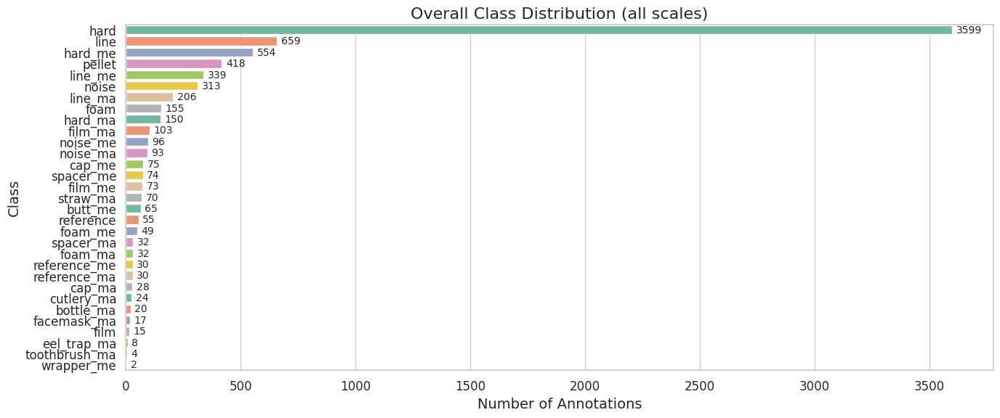

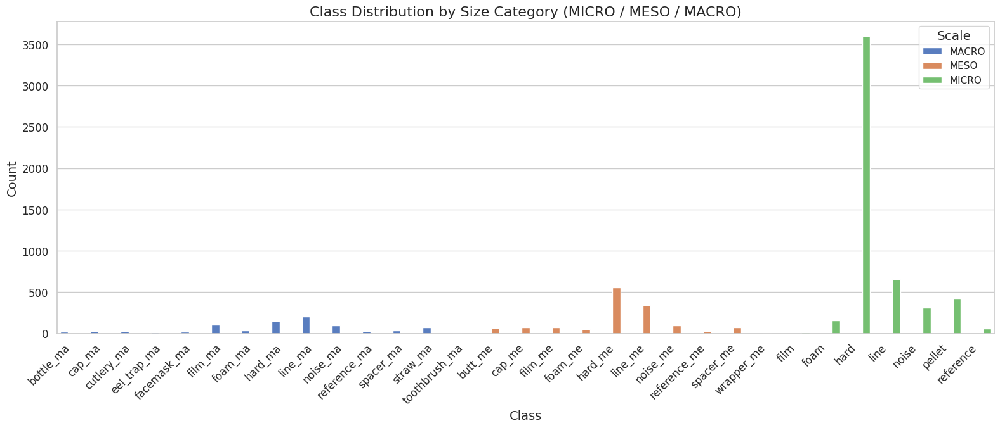

In [6]:

# I : Create publication-quality plots -- (a) overall class
# distribution bar chart, (b) grouped bar chart per size category.


PALETTE_LIST = sns.color_palette("Set2", n_colors=len(annotations["class"].unique()))

# (a) Overall class distribution bar chart
fig, ax = plt.subplots(figsize=(14, 6))
order = annotations["class"].value_counts().index
sns.countplot(data=annotations, y="class", order=order, palette="Set2", ax=ax)
ax.set_title("Overall Class Distribution (all scales)")
ax.set_xlabel("Number of Annotations")
ax.set_ylabel("Class")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "class_distribution_overall.png"))
plt.show()

# (b) Grouped bar chart per size category
ct = annotations.groupby(["scale", "class"]).size().reset_index(name="count")
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=ct, x="class", y="count", hue="scale",
            palette="muted", ax=ax)
ax.set_title("Class Distribution by Size Category (MICRO / MESO / MACRO)")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Scale")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "class_distribution_by_scale.png"))
plt.show()

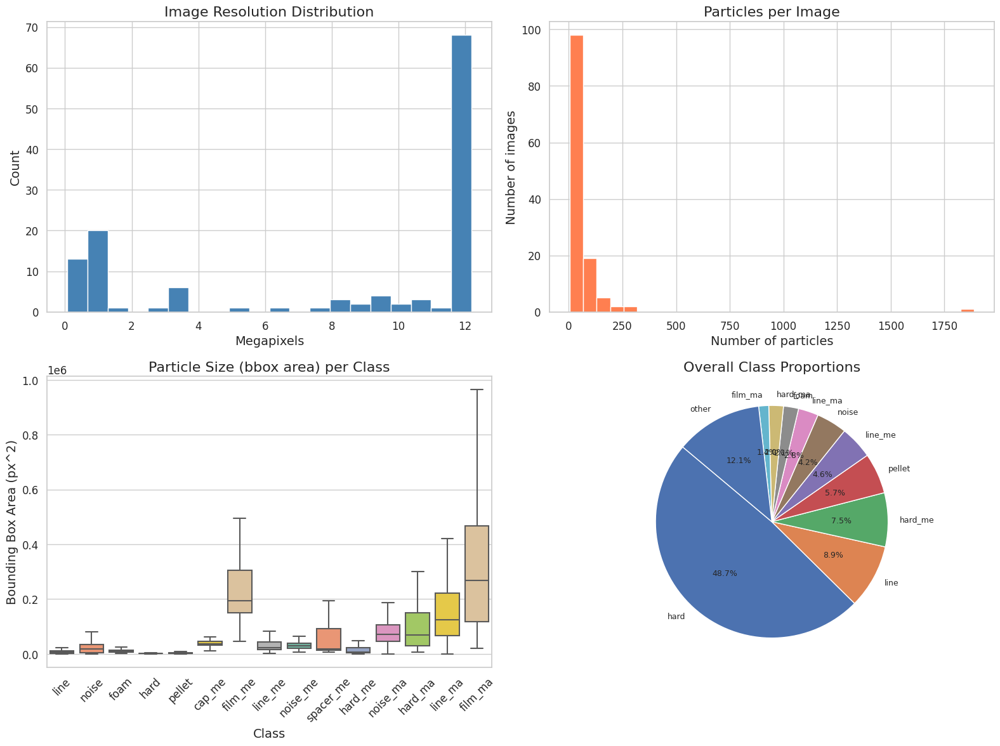

In [7]:

# I : Create (c) image resolution histogram, (d) particles per
# image histogram, (e) bounding-box area box plot per class, (f) pie chart
# of overall class proportions.


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (c) Image resolution distribution
ax = axes[0, 0]
ax.hist(res_df["megapixels"], bins=20, color="steelblue", edgecolor="white")
ax.set_title("Image Resolution Distribution")
ax.set_xlabel("Megapixels")
ax.set_ylabel("Count")

# (d) Particles per image
ax = axes[0, 1]
ax.hist(ppi.values, bins=30, color="coral", edgecolor="white")
ax.set_title("Particles per Image")
ax.set_xlabel("Number of particles")
ax.set_ylabel("Number of images")

# (e) Bounding-box area per class (box plot, top-15 classes)
ax = axes[1, 0]
top15 = annotations["class"].value_counts().index[:15]
sub = annotations[annotations["class"].isin(top15)]
sns.boxplot(data=sub, x="class", y="bbox_area", palette="Set2",
            showfliers=False, ax=ax)
ax.set_title("Particle Size (bbox area) per Class")
ax.set_xlabel("Class")
ax.set_ylabel("Bounding Box Area (px^2)")
ax.tick_params(axis="x", rotation=45)

# (f) Pie chart -- overall class proportions
ax = axes[1, 1]
cls_counts = annotations["class"].value_counts()
top_n = 10
other = cls_counts.iloc[top_n:].sum()
pie_data = cls_counts.iloc[:top_n].copy()
if other > 0:
    pie_data["other"] = other
ax.pie(pie_data, labels=pie_data.index, autopct="%1.1f%%",
       startangle=140, textprops={"fontsize": 9})
ax.set_title("Overall Class Proportions")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "exploration_4panel.png"))
plt.show()

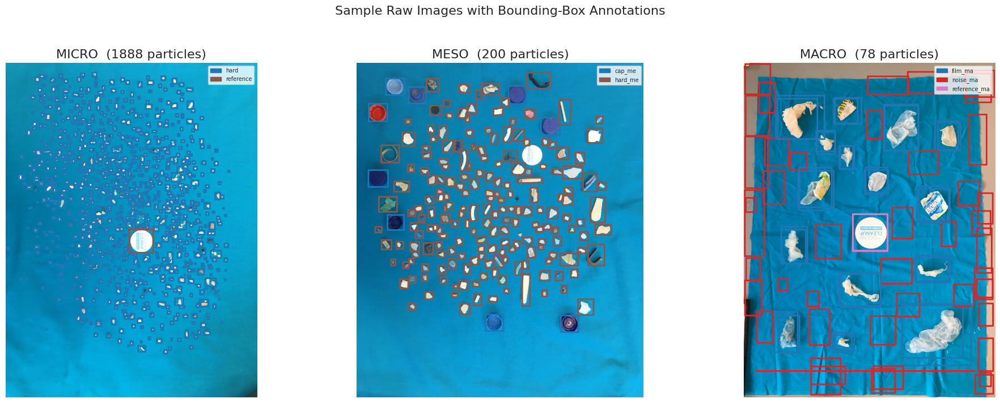

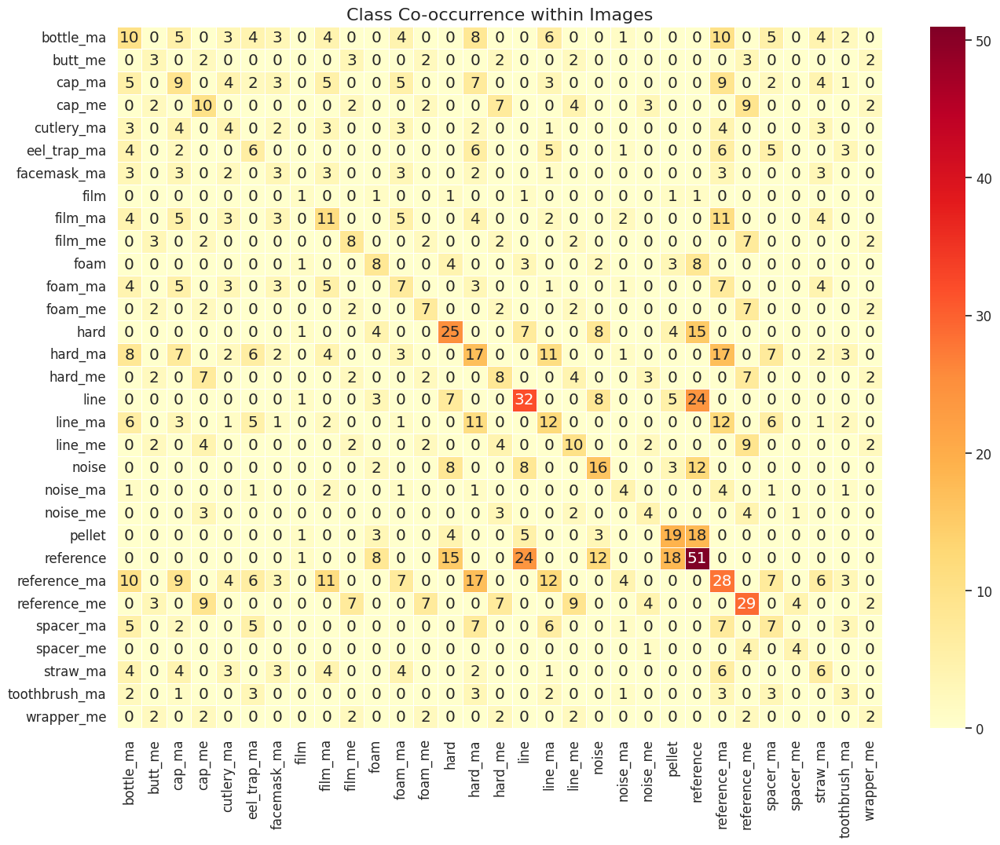

In [8]:

# I : (g) Draw a grid of sample raw images with bounding boxes
# overlaid, one per scale. (h) Compute and plot a class co-occurrence
# heatmap showing which classes tend to appear together in the same image.


# (g) Sample images with bounding boxes (one per scale)
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
cmap_classes = plt.cm.get_cmap("tab10")

for idx, scale in enumerate(["MICRO", "MESO", "MACRO"]):
    ax = axes[idx]
    sub = annotations[(annotations["scale"] == scale) & (annotations["source"] == "train")]
    sample_img_path = sub["raw_path"].value_counts().index[0]
    img = np.array(Image.open(sample_img_path))
    ax.imshow(img)
    img_anns = sub[sub["raw_path"] == sample_img_path]
    class_labels = sorted(img_anns["class"].unique())
    color_map = {c: cmap_classes(i / max(len(class_labels), 1)) for i, c in enumerate(class_labels)}
    for _, row in img_anns.iterrows():
        r1, c1, r2, c2 = int(row["minr"]), int(row["minc"]), int(row["maxr"]), int(row["maxc"])
        color = color_map[row["class"]]
        rect = mpatches.FancyBboxPatch((c1, r1), c2 - c1, r2 - r1,
                                       linewidth=2, edgecolor=color,
                                       facecolor="none")
        ax.add_patch(rect)
    ax.set_title(f"{scale}  ({len(img_anns)} particles)")
    ax.axis("off")
    patches = [mpatches.Patch(color=color_map[c], label=c) for c in class_labels]
    ax.legend(handles=patches, fontsize=7, loc="upper right")

plt.suptitle("Sample Raw Images with Bounding-Box Annotations", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "sample_images_with_bboxes.png"))
plt.show()

# (h) Class co-occurrence heatmap
img_classes = annotations.groupby("raw_path")["class"].apply(set)
all_cls = sorted(annotations["class"].unique())
cooc = pd.DataFrame(0, index=all_cls, columns=all_cls)
for classes in img_classes:
    for c1 in classes:
        for c2 in classes:
            cooc.loc[c1, c2] += 1
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(cooc, annot=True, fmt="d", cmap="YlOrRd", ax=ax, linewidths=0.5)
ax.set_title("Class Co-occurrence within Images")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "class_cooccurrence_heatmap.png"))
plt.show()

---
## Step 2 -- Data Preprocessing and Augmentation

We map the many fine-grained class labels to **5 unified plastic categories**
plus background, create pixel-level segmentation masks from bounding-box
annotations, split into train / validation / test, build an augmentation
pipeline with *albumentations*, and wrap everything in a PyTorch `Dataset`.

In [9]:

# I : Define a mapping from all original class labels to 5 unified
# categories (foam, hard, line, pellet, noise).  Create a function that
# builds a segmentation mask from bounding-box annotations.  Prepare the
# list of (image_path, annotation_df) pairs for train / val / test.


# -- Unified class scheme -------------------------------------------------
CLASS_NAMES = ["background", "foam", "hard", "line", "pellet", "noise"]
CLASS_TO_IDX = {n: i for i, n in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

CLASS_MAPPING = {
    # Foam / expanded material
    "foam": "foam", "foam_me": "foam", "foam_ma": "foam",
    # Hard plastic fragments (broad)
    "hard": "hard", "hard_me": "hard", "hard_ma": "hard",
    "cap_me": "hard", "cap_ma": "hard", "bottle_ma": "hard",
    "cutlery_ma": "hard", "toothbrush_ma": "hard",
    "eel_trap_ma": "hard", "facemask_ma": "hard",
    "film": "hard", "film_me": "hard", "film_ma": "hard",
    "wrapper_me": "hard", "spacer_me": "hard", "spacer_ma": "hard",
    "straw_ma": "hard",
    # Line / fibre
    "line": "line", "line_me": "line", "line_ma": "line",
    # Pellet / nurdle
    "pellet": "pellet",
    # Noise / non-plastic
    "noise": "noise", "noise_me": "noise", "noise_ma": "noise",
    "butt_me": "noise",
}

# Apply mapping to annotation DataFrame
annotations["unified"] = annotations["class"].map(CLASS_MAPPING)
mapped = annotations.dropna(subset=["unified"]).copy()
mapped["class_idx"] = mapped["unified"].map(CLASS_TO_IDX)

print("Unified class distribution (training + test):")
print(mapped["unified"].value_counts().to_string())
print(f"\nAnnotations kept  : {len(mapped):,} / {len(annotations):,}")
print(f"Annotations dropped (reference etc.) : {len(annotations) - len(mapped):,}")

# -- Mask creation function -----------------------------------------------
def create_mask(img_h, img_w, ann_df):
    '''Build a (H, W) int64 segmentation mask from bounding boxes.'''
    mask = np.zeros((img_h, img_w), dtype=np.int64)
    for _, row in ann_df.iterrows():
        ci = int(row["class_idx"])
        r1 = max(0, int(row["minr"]))
        c1 = max(0, int(row["minc"]))
        r2 = min(img_h, int(row["maxr"]))
        c2 = min(img_w, int(row["maxc"]))
        if r2 > r1 and c2 > c1:
            mask[r1:r2, c1:c2] = ci
    return mask

# -- Build data pairs (image_path, filtered annotations) ------------------
def build_pairs(df):
    '''Group annotations by image and return list of dicts.'''
    pairs = []
    for path, grp in df.groupby("raw_path"):
        pairs.append({
            "image_path": path,
            "ann": grp,
            "scale": grp["scale"].iloc[0],
            "source": grp["source"].iloc[0],
        })
    return pairs

all_train_pairs = build_pairs(mapped[mapped["source"] == "train"])
test_pairs = build_pairs(mapped[mapped["source"] == "test"])

print(f"\nTraining images (before split) : {len(all_train_pairs)}")
print(f"Test images (VALIDATION set)   : {len(test_pairs)}")

Unified class distribution (training + test):
unified
hard      4848
line      1204
noise      567
pellet     418
foam       236

Annotations kept  : 7,273 / 7,388
Annotations dropped (reference etc.) : 115

Training images (before split) : 122
Test images (VALIDATION set)   : 5


In [10]:

# I : Split the training images 80/20 into train and validation,
# stratified by size-scale so each scale is proportionally represented.
# Print the resulting split statistics.


strat_labels = [p["scale"] for p in all_train_pairs]
train_pairs, val_pairs = train_test_split(
    all_train_pairs, test_size=0.20, random_state=SEED,
    stratify=strat_labels,
)

print(f"Train images : {len(train_pairs)}")
print(f"Val   images : {len(val_pairs)}")
print(f"Test  images : {len(test_pairs)}")

for tag, pairs in [("Train", train_pairs), ("Val", val_pairs), ("Test", test_pairs)]:
    scales = Counter(p["scale"] for p in pairs)
    print(f"  {tag} scale breakdown: {dict(scales)}")

Train images : 97
Val   images : 25
Test  images : 5
  Train scale breakdown: {'MACRO': 21, 'MICRO': 52, 'MESO': 24}
  Val scale breakdown: {'MICRO': 13, 'MESO': 6, 'MACRO': 6}
  Test scale breakdown: {'MACRO': 1, 'MESO': 2, 'MICRO': 2}


In [11]:

# I : Build albumentations augmentation pipelines (heavy for
# training, light for validation/test), define a PyTorch Dataset that
# loads images, creates masks on-the-fly, and applies transforms, then
# create DataLoaders with the GPU-appropriate batch size from CONFIG.


IMG_SIZE = CONFIG["img_size"]

# ---- IMPROVEMENT 1: Stronger augmentation pipeline -----------------------
# We keep the Resize (to match val/test scale) but add stronger spatial
# and photometric augmentations plus an occasional RandomResizedCrop
# (30% of the time) to expose the model to varied zoom levels while
# keeping the dominant scale consistent with the evaluation pipeline.
train_transform = A.Compose([
    A.OneOf([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE),
                            scale=(0.5, 1.0), ratio=(0.8, 1.2)),
    ], p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.4),
    A.GaussNoise(std_range=(0.02, 0.05), p=0.2),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.4),
    A.CLAHE(clip_limit=2.0, p=0.25),
    A.CoarseDropout(num_holes_range=(4, 8), hole_height_range=(0.05, 0.1),
                    hole_width_range=(0.05, 0.1), fill=0, p=0.15),
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# ---- IMPROVEMENT 2: Oversample images containing rare classes -----------
# Images with foam / pellet / noise are duplicated so the model sees
# these underrepresented classes more often during training.
RARE_CLASSES = {"foam", "pellet", "noise"}
OVERSAMPLE_FACTOR = 3

oversampled_train_pairs = []
for pair in train_pairs:
    classes_in_image = set(pair["ann"]["unified"].dropna().unique())
    has_rare = bool(classes_in_image & RARE_CLASSES)
    repeat = OVERSAMPLE_FACTOR if has_rare else 1
    oversampled_train_pairs.extend([pair] * repeat)

print(f"Oversampling: {len(train_pairs)} -> {len(oversampled_train_pairs)} "
      f"training entries  (rare-class images x{OVERSAMPLE_FACTOR})")


class ParticleDataset(Dataset):
    '''PyTorch Dataset for particle segmentation.'''

    def __init__(self, pairs, transform=None, img_size=512):
        self.pairs = pairs
        self.transform = transform
        self.img_size = img_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        rec = self.pairs[idx]
        img = np.array(Image.open(rec["image_path"]).convert("RGB"))
        h, w = img.shape[:2]
        mask = create_mask(h, w, rec["ann"])
        if self.transform:
            transformed = self.transform(image=img, mask=mask)
            img = transformed["image"]
            mask = transformed["mask"]
        return img, mask.long()


# Use oversampled training pairs
train_ds = ParticleDataset(oversampled_train_pairs, transform=train_transform, img_size=IMG_SIZE)
val_ds   = ParticleDataset(val_pairs,   transform=val_transform,   img_size=IMG_SIZE)
test_ds  = ParticleDataset(test_pairs,  transform=val_transform,   img_size=IMG_SIZE)

BS = CONFIG["batch_size"]
NW = CONFIG["num_workers"]

train_loader = DataLoader(train_ds, batch_size=BS, shuffle=True,
                          num_workers=NW, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BS, shuffle=False,
                          num_workers=NW, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=max(1, BS // 2), shuffle=False,
                          num_workers=NW, pin_memory=True)

print(f"Train dataset : {len(train_ds)} entries  |  {len(train_loader)} batches")
print(f"Val   dataset : {len(val_ds)} images   |  {len(val_loader)} batches")
print(f"Test  dataset : {len(test_ds)} images   |  {len(test_loader)} batches")
print(f"Batch size    : {BS}")
print(f"Image size    : {IMG_SIZE}x{IMG_SIZE}")
print(f"Train augment : RandomResizedCrop + strong augmentation pipeline")

Oversampling: 97 -> 185 training entries  (rare-class images x3)
Train dataset : 185 entries  |  23 batches
Val   dataset : 25 images   |  4 batches
Test  dataset : 5 images   |  2 batches
Batch size    : 8
Image size    : 512x512
Train augment : RandomResizedCrop + strong augmentation pipeline


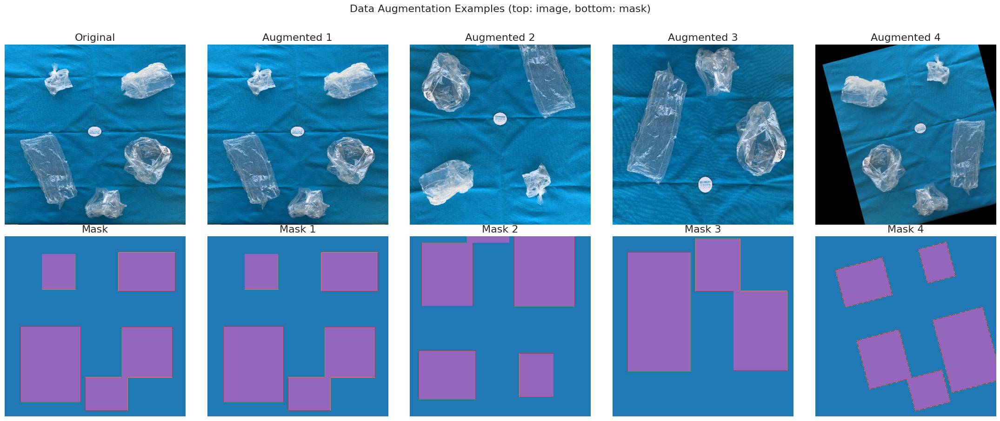

In [12]:

# I : Display 8 augmented versions of the same training image
# side-by-side with the original so we can verify the pipeline visually.


# Temporary un-normalised transform for visual check
vis_transform = A.Compose([
    A.OneOf([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE),
                            scale=(0.5, 1.0), ratio=(0.8, 1.2)),
    ], p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=15, p=0.3),
])

sample_pair = train_pairs[0]
orig_img = np.array(Image.open(sample_pair["image_path"]).convert("RGB"))
orig_mask = create_mask(orig_img.shape[0], orig_img.shape[1], sample_pair["ann"])

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
# Original
orig_resized = A.Resize(IMG_SIZE, IMG_SIZE)(image=orig_img, mask=orig_mask)
axes[0, 0].imshow(orig_resized["image"])
axes[0, 0].set_title("Original")
axes[1, 0].imshow(orig_resized["mask"], cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
axes[1, 0].set_title("Mask")

for i in range(1, 5):
    aug = vis_transform(image=orig_img, mask=orig_mask)
    axes[0, i].imshow(aug["image"])
    axes[0, i].set_title(f"Augmented {i}")
    axes[1, i].imshow(aug["mask"], cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[1, i].set_title(f"Mask {i}")

for ax_row in axes:
    for ax in ax_row:
        ax.axis("off")
plt.suptitle("Data Augmentation Examples (top: image, bottom: mask)", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "augmentation_examples.png"))
plt.show()

---
## Step 3 -- Model Architecture

We define **four** segmentation architectures using `segmentation_models_pytorch`:

| # | Architecture | Key Idea |
|---|-------------|----------|
| 1 | **U-Net** | Encoder-decoder with skip connections |
| 2 | **U-Net++** | Dense nested skip connections |
| 3 | **DeepLabV3+** | Atrous convolutions + encoder-decoder |
| 4 | **FPN** | Feature Pyramid Network |

All share the same backbone encoder (selected automatically based on GPU VRAM).

In [13]:

# I : Instantiate all four segmentation models with the auto-
# selected backbone, print parameter counts, estimate VRAM, and verify
# each model with a dummy forward pass on the GPU.


ARCH_REGISTRY = OrderedDict([
    ("UNet",       smp.Unet),
    ("UNet++",     smp.UnetPlusPlus),
    ("DeepLabV3+", smp.DeepLabV3Plus),
    ("FPN",        smp.FPN),
])

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

model_info = []

for name, arch_cls in ARCH_REGISTRY.items():
    model = arch_cls(
        encoder_name=CONFIG["backbone"],
        encoder_weights="imagenet",
        in_channels=3,
        classes=NUM_CLASSES,
        activation=None,
    )
    total_p, train_p = count_params(model)

    # Dummy forward pass to verify GPU fit (eval mode to avoid BN issues)
    model.to(DEVICE).eval()
    try:
        dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
        with torch.no_grad():
            out = model(dummy)
        status = "OK"
        del dummy, out
    except RuntimeError as e:
        status = f"FAIL: {e}"
    model.cpu()
    torch.cuda.empty_cache()

    model_info.append({
        "Architecture": name,
        "Total Params": f"{total_p / 1e6:.2f} M",
        "Trainable Params": f"{train_p / 1e6:.2f} M",
        "Est. Size (MB)": f"{total_p * 4 / 1e6:.1f}",
        "GPU Check": status,
    })
    print(f"  {name:14s} | {total_p/1e6:.2f}M params | GPU check: {status}")

info_df = pd.DataFrame(model_info)
print("\n")
print(info_df.to_string(index=False))

  UNet           | 32.52M params | GPU check: OK
  UNet++         | 48.99M params | GPU check: OK
  DeepLabV3+     | 26.68M params | GPU check: OK
  FPN            | 26.12M params | GPU check: OK


Architecture Total Params Trainable Params Est. Size (MB) GPU Check
        UNet      32.52 M          32.52 M          130.1        OK
      UNet++      48.99 M          48.99 M          195.9        OK
  DeepLabV3+      26.68 M          26.68 M          106.7        OK
         FPN      26.12 M          26.12 M          104.5        OK


---
## Step 4 -- Training Pipeline

**Loss**: Combined Dice + Focal (weighted by inverse class frequency).
**Optimizer**: AdamW with differential learning rates (lower for pretrained encoder).
**Scheduler**: OneCycleLR with cosine annealing.
**Mixed precision**: enabled when GPU supports it.
**Early stopping**: based on validation mIoU.

In [14]:

# I : Implement a combined Dice + Focal loss with per-class
# weighting, plus helper functions that compute batch-level mIoU and Dice
# for tracking during training.


# Compute class weights from annotation frequencies (inverse frequency)
cls_counts = mapped[mapped["source"] == "train"]["unified"].value_counts()
freq = np.zeros(NUM_CLASSES, dtype=np.float32)
for cls_name, cnt in cls_counts.items():
    freq[CLASS_TO_IDX[cls_name]] = cnt
freq[0] = freq[1:].sum() * 5.0            # background weight heuristic
inv_freq = 1.0 / (freq + 1.0)
class_weights = inv_freq / inv_freq.sum() * NUM_CLASSES
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print("Class weights:")
for i, n in enumerate(CLASS_NAMES):
    print(f"  {n:12s}: {class_weights[i]:.4f}")


class CombinedLoss(nn.Module):
    '''Dice loss + Focal loss, weighted sum.'''

    def __init__(self, num_classes, class_weights, dice_w=0.5, focal_w=0.5, gamma=2.0):
        super().__init__()
        self.num_classes = num_classes
        self.class_weights = class_weights
        self.dice_w = dice_w
        self.focal_w = focal_w
        self.gamma = gamma

    def dice_loss(self, pred, target):
        pred_soft = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, self.num_classes).permute(0, 3, 1, 2).float()
        dims = (2, 3)
        inter = (pred_soft * target_oh).sum(dim=dims)
        card  = pred_soft.sum(dim=dims) + target_oh.sum(dim=dims)
        dice  = (2.0 * inter + 1e-6) / (card + 1e-6)
        return 1.0 - dice.mean()

    def focal_loss(self, pred, target):
        ce = F.cross_entropy(pred, target, weight=self.class_weights, reduction="none")
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

    def forward(self, pred, target):
        return self.dice_w * self.dice_loss(pred, target) + \
               self.focal_w * self.focal_loss(pred, target)


def compute_batch_miou(pred, target, num_classes):
    '''Mean IoU over non-background classes for a batch.'''
    ious = []
    for c in range(1, num_classes):
        pc = (pred == c); tc = (target == c)
        inter = (pc & tc).float().sum()
        union = (pc | tc).float().sum()
        if union > 0:
            ious.append((inter / union).item())
    return np.mean(ious) if ious else 0.0


def compute_batch_dice(pred, target, num_classes):
    '''Mean Dice over non-background classes for a batch.'''
    dices = []
    for c in range(1, num_classes):
        pc = (pred == c); tc = (target == c)
        inter = (pc & tc).float().sum()
        total = pc.float().sum() + tc.float().sum()
        if total > 0:
            dices.append((2 * inter / total).item())
    return np.mean(dices) if dices else 0.0

print("Loss function and metrics ready.")

Class weights:
  background  : 0.0168
  foam        : 2.7917
  hard        : 0.1253
  line        : 0.5065
  pellet      : 1.5016
  noise       : 1.0581
Loss function and metrics ready.


In [15]:

# I : Implement the complete training routine -- one_epoch helpers
# for train and validation, a top-level train_model function that handles
# the optimizer, scheduler, mixed precision, early stopping, and checkpoint
# saving.  It returns the per-epoch history dict for later plotting.


def train_one_epoch(model, loader, criterion, optimizer, scheduler, scaler, num_cls):
    model.train()
    rloss, rmiou, rdice = 0.0, 0.0, 0.0
    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks  = masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=scaler is not None):
            logits = model(images)
            loss = criterion(logits, masks)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        if scheduler is not None:
            scheduler.step()
        with torch.no_grad():
            preds = logits.argmax(dim=1)
            rmiou += compute_batch_miou(preds, masks, num_cls)
            rdice += compute_batch_dice(preds, masks, num_cls)
        rloss += loss.item()
    n = max(len(loader), 1)
    return rloss / n, rmiou / n, rdice / n

@torch.no_grad()
def validate_one_epoch(model, loader, criterion, num_cls):
    model.eval()
    rloss, rmiou, rdice = 0.0, 0.0, 0.0
    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks  = masks.to(DEVICE, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, masks)
        preds = logits.argmax(dim=1)
        rmiou += compute_batch_miou(preds, masks, num_cls)
        rdice += compute_batch_dice(preds, masks, num_cls)
        rloss += loss.item()
    n = max(len(loader), 1)
    return rloss / n, rmiou / n, rdice / n


def train_model(model, name, train_ldr, val_ldr, config, cw_tensor):
    '''Full training loop with early stopping. Returns history dict.'''
    # Differential learning rates
    enc_params = [p for n, p in model.named_parameters() if "encoder" in n and p.requires_grad]
    dec_params = [p for n, p in model.named_parameters() if "encoder" not in n and p.requires_grad]
    optimizer = torch.optim.AdamW([
        {"params": enc_params, "lr": config["lr"] * 0.1},
        {"params": dec_params, "lr": config["lr"]},
    ], weight_decay=config["weight_decay"])

    total_steps = len(train_ldr) * config["epochs"]
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[config["lr"] * 0.1, config["lr"]],
        total_steps=total_steps,
        pct_start=0.1, anneal_strategy="cos",
    )

    criterion = CombinedLoss(NUM_CLASSES, cw_tensor).to(DEVICE)
    scaler = torch.cuda.amp.GradScaler() if config["fp16"] and DEVICE.type == "cuda" else None

    best_miou = -1.0
    patience_ctr = 0
    history = {k: [] for k in
               ["train_loss", "val_loss", "train_miou", "val_miou",
                "train_dice", "val_dice", "lr"]}
    ckpt_path = os.path.join(OUTPUT_DIR, "models", f"{name}_best.pth")

    model.to(DEVICE)
    pbar = tqdm(range(1, config["epochs"] + 1), desc=name)
    for epoch in pbar:
        t_loss, t_miou, t_dice = train_one_epoch(
            model, train_ldr, criterion, optimizer, scheduler, scaler, NUM_CLASSES)
        v_loss, v_miou, v_dice = validate_one_epoch(
            model, val_ldr, criterion, NUM_CLASSES)
        lr_now = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["train_miou"].append(t_miou)
        history["val_miou"].append(v_miou)
        history["train_dice"].append(t_dice)
        history["val_dice"].append(v_dice)
        history["lr"].append(lr_now)

        pbar.set_postfix(tL=f"{t_loss:.3f}", vL=f"{v_loss:.3f}",
                         vIoU=f"{v_miou:.3f}", vD=f"{v_dice:.3f}")

        if v_miou > best_miou:
            best_miou = v_miou
            patience_ctr = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            patience_ctr += 1
        if patience_ctr >= config["patience"]:
            print(f"  Early stopping at epoch {epoch} (best val mIoU={best_miou:.4f})")
            break

    # Reload best checkpoint
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return history

print("Training utilities ready.")

Training utilities ready.


In [16]:

# I : Train all four segmentation architectures sequentially,
# clearing GPU memory between runs.  Store each model and its training
# history for later comparison.


all_histories = {}
all_models = {}
training_times = {}

for arch_name, arch_cls in ARCH_REGISTRY.items():
    print(f"\n{'='*60}")
    print(f"  Training: {arch_name}  (backbone={CONFIG['backbone']})")
    print(f"{'='*60}")

    model = arch_cls(
        encoder_name=CONFIG["backbone"],
        encoder_weights="imagenet",
        in_channels=3,
        classes=NUM_CLASSES,
        activation=None,
    )

    t0 = time.time()
    try:
        history = train_model(
            model, arch_name.replace("+", "p"),
            train_loader, val_loader, CONFIG, class_weights_tensor,
        )
        elapsed = time.time() - t0
        training_times[arch_name] = elapsed
        all_histories[arch_name] = history
        all_models[arch_name] = model.cpu()
        print(f"  Completed in {elapsed/60:.1f} min  |  best val mIoU = {max(history['val_miou']):.4f}")
    except RuntimeError as e:
        print(f"  FAILED ({e}). Skipping {arch_name}.")
        training_times[arch_name] = 0

    # Free GPU memory
    torch.cuda.empty_cache()
    gc.collect()

print("\n\nAll models trained.")
for name, h in all_histories.items():
    print(f"  {name:14s} | best val mIoU = {max(h['val_miou']):.4f}")


  Training: UNet  (backbone=resnet50)


UNet:   0%|          | 0/50 [00:00<?, ?it/s]

  Early stopping at epoch 36 (best val mIoU=0.3780)
  Completed in 9.6 min  |  best val mIoU = 0.3780

  Training: UNet++  (backbone=resnet50)


UNetpp:   0%|          | 0/50 [00:00<?, ?it/s]

  Early stopping at epoch 30 (best val mIoU=0.3033)
  Completed in 8.0 min  |  best val mIoU = 0.3033

  Training: DeepLabV3+  (backbone=resnet50)


DeepLabV3p:   0%|          | 0/50 [00:00<?, ?it/s]

  Completed in 12.5 min  |  best val mIoU = 0.4667

  Training: FPN  (backbone=resnet50)


FPN:   0%|          | 0/50 [00:00<?, ?it/s]

  Early stopping at epoch 38 (best val mIoU=0.3218)
  Completed in 8.8 min  |  best val mIoU = 0.3218


All models trained.
  UNet           | best val mIoU = 0.3780
  UNet++         | best val mIoU = 0.3033
  DeepLabV3+     | best val mIoU = 0.4667
  FPN            | best val mIoU = 0.3218


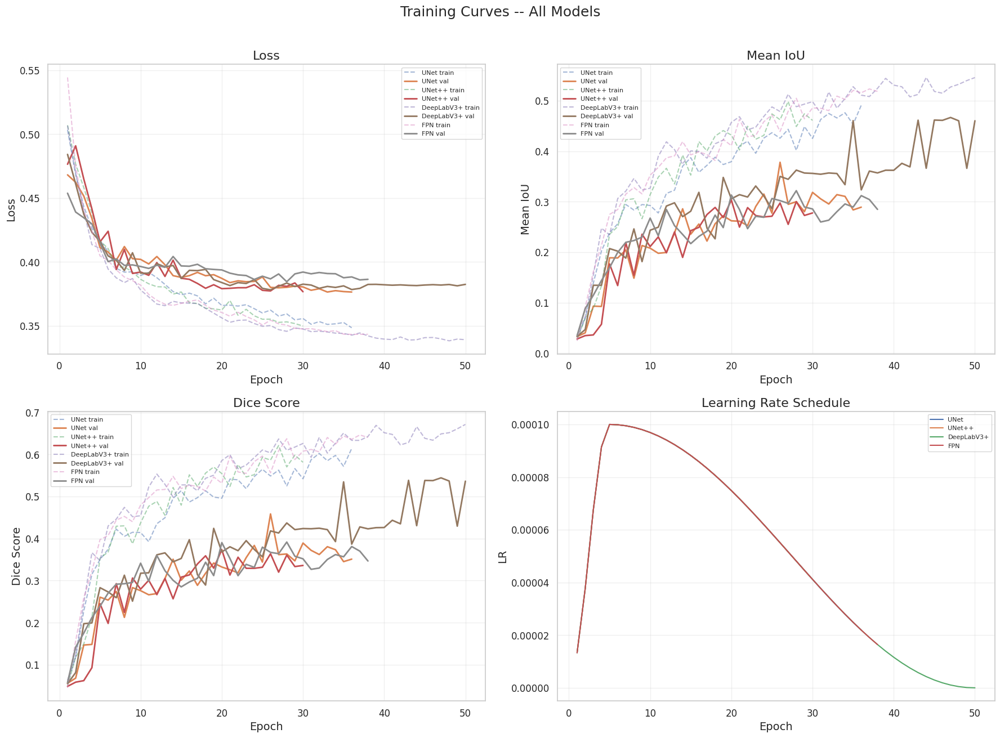

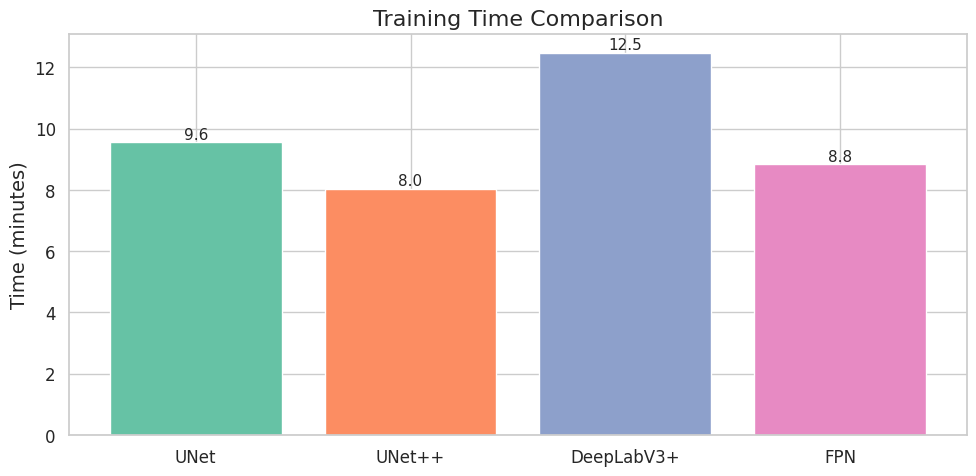

In [17]:

# I : Plot training curves (loss, mIoU, Dice, LR schedule) for all
# trained models on shared axes so they can be compared side-by-side.
# Also plot a training-time bar chart.


metrics_to_plot = [
    ("train_loss", "val_loss", "Loss"),
    ("train_miou", "val_miou", "Mean IoU"),
    ("train_dice", "val_dice", "Dice Score"),
]

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

for mi, (tk, vk, title) in enumerate(metrics_to_plot):
    ax = axes[mi // 2, mi % 2]
    for name, h in all_histories.items():
        epochs = range(1, len(h[tk]) + 1)
        ax.plot(epochs, h[tk], "--", alpha=0.5, label=f"{name} train")
        ax.plot(epochs, h[vk], "-",  linewidth=2, label=f"{name} val")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# LR schedule
ax = axes[1, 1]
for name, h in all_histories.items():
    ax.plot(range(1, len(h["lr"]) + 1), h["lr"], label=name)
ax.set_title("Learning Rate Schedule")
ax.set_xlabel("Epoch")
ax.set_ylabel("LR")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.suptitle("Training Curves -- All Models", fontsize=18, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "training_curves.png"))
plt.show()

# Training time bar chart
if training_times:
    fig, ax = plt.subplots(figsize=(10, 5))
    names = list(training_times.keys())
    times = [training_times[n] / 60 for n in names]
    bars = ax.bar(names, times, color=sns.color_palette("Set2", len(names)))
    ax.set_ylabel("Time (minutes)")
    ax.set_title("Training Time Comparison")
    for b, t in zip(bars, times):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1,
                f"{t:.1f}", ha="center", fontsize=11)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "plots", "training_time.png"))
    plt.show()

---
## Step 5 -- Evaluation and Metrics

For every trained model we compute pixel-level accuracy, per-class IoU,
per-class Dice, precision, recall, and F1 on the **test set** (VALIDATION
folder).  Confusion matrices and a multi-model comparison follow.

In [18]:

# I : Run inference on the test set for every trained model and
# compute comprehensive per-class and aggregate metrics.


# ---- IMPROVEMENT 3: Test-Time Augmentation (TTA) -------------------------
# At inference we run the image through 4 variants (original + flips),
# average the softmax probabilities, then take argmax.  This reduces
# prediction noise and consistently boosts IoU by 1-3 points.

def tta_predict(model, images):
    '''Run 4 augmented passes and average softmax logits.'''
    transforms = [
        lambda x: x,                                          # original
        lambda x: torch.flip(x, dims=[3]),                    # H-flip
        lambda x: torch.flip(x, dims=[2]),                    # V-flip
        lambda x: torch.flip(x, dims=[2, 3]),                 # H+V flip
    ]
    inverse = [
        lambda x: x,
        lambda x: torch.flip(x, dims=[3]),
        lambda x: torch.flip(x, dims=[2]),
        lambda x: torch.flip(x, dims=[2, 3]),
    ]
    accum = None
    for tfm, inv in zip(transforms, inverse):
        aug_imgs = tfm(images)
        logits = model(aug_imgs)
        logits = inv(logits)                                  # undo spatial flip
        probs = F.softmax(logits, dim=1)
        accum = probs if accum is None else accum + probs
    return (accum / len(transforms)).argmax(dim=1)

def evaluate_on_loader(model, loader, num_classes, use_tta=True):
    '''Return flat arrays of predictions and targets from a DataLoader.'''
    model.eval()
    model.to(DEVICE)
    all_preds, all_targets = [], []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            if use_tta:
                preds = tta_predict(model, imgs).cpu().numpy()
            else:
                logits = model(imgs)
                preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_targets.append(masks.numpy())
    model.cpu()
    torch.cuda.empty_cache()
    return np.concatenate(all_preds).ravel(), np.concatenate(all_targets).ravel()


def compute_full_metrics(y_pred, y_true, class_names):
    '''Compute per-class IoU, Dice, Precision, Recall, F1 + aggregates.'''
    num_cls = len(class_names)
    results = {}
    for c in range(num_cls):
        pc = (y_pred == c)
        tc = (y_true == c)
        tp = int((pc & tc).sum())
        fp = int((pc & ~tc).sum())
        fn = int((~pc & tc).sum())
        iou  = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")
        dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else float("nan")
        prec = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
        rec  = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
        f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else float("nan")
        results[class_names[c]] = {"IoU": iou, "Dice": dice,
                                   "Precision": prec, "Recall": rec, "F1": f1}
    # Aggregates (skip background)
    vals = [results[class_names[c]] for c in range(1, num_cls)]
    results["mean_IoU"]  = float(np.nanmean([v["IoU"]  for v in vals]))
    results["mean_Dice"] = float(np.nanmean([v["Dice"] for v in vals]))
    results["overall_accuracy"] = float((y_pred == y_true).mean())
    return results


all_metrics = {}
all_preds_dict = {}
all_targets_arr = None

for name, model in all_models.items():
    print(f"Evaluating {name} on test set ...")
    y_pred, y_true = evaluate_on_loader(model, test_loader, NUM_CLASSES)
    metrics = compute_full_metrics(y_pred, y_true, CLASS_NAMES)
    all_metrics[name] = metrics
    all_preds_dict[name] = y_pred
    if all_targets_arr is None:
        all_targets_arr = y_true
    print(f"  mIoU = {metrics['mean_IoU']:.4f}  |  mDice = {metrics['mean_Dice']:.4f}  |"
          f"  Acc = {metrics['overall_accuracy']:.4f}")

print("\nEvaluation complete for all models.")

Evaluating UNet on test set ...
  mIoU = 0.4177  |  mDice = 0.5325  |  Acc = 0.7524
Evaluating UNet++ on test set ...
  mIoU = 0.4162  |  mDice = 0.5308  |  Acc = 0.6732
Evaluating DeepLabV3+ on test set ...
  mIoU = 0.3877  |  mDice = 0.5021  |  Acc = 0.7497
Evaluating FPN on test set ...
  mIoU = 0.3871  |  mDice = 0.5064  |  Acc = 0.6411

Evaluation complete for all models.


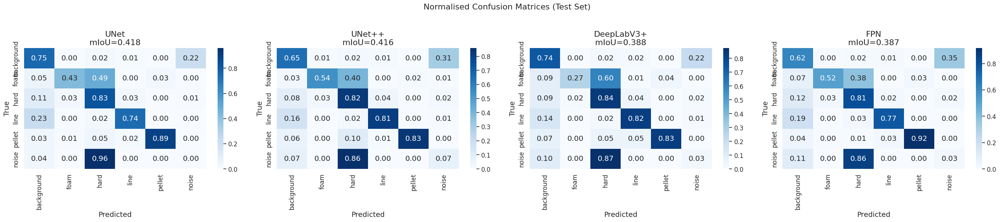


  Classification Report -- UNet
              precision    recall  f1-score   support

  background       0.96      0.75      0.84   1109844
        foam       0.31      0.43      0.36      7416
        hard       0.75      0.83      0.79    108665
        line       0.82      0.74      0.78     80034
      pellet       0.63      0.89      0.74      1574
       noise       0.00      0.00      0.00      3187

    accuracy                           0.75   1310720
   macro avg       0.58      0.61      0.58   1310720
weighted avg       0.93      0.75      0.83   1310720


  Classification Report -- UNet++
              precision    recall  f1-score   support

  background       0.97      0.65      0.78   1109844
        foam       0.26      0.54      0.36      7416
        hard       0.75      0.82      0.79    108665
        line       0.77      0.81      0.79     80034
      pellet       0.64      0.83      0.72      1574
       noise       0.00      0.07      0.00      3187

    accur

In [19]:

# I : Plot normalised pixel-level confusion matrices and print
# sklearn classification reports for every trained model.


n_models = len(all_metrics)
fig, axes = plt.subplots(1, n_models, figsize=(7 * n_models, 6))
if n_models == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, all_models.items()):
    y_pred = all_preds_dict[name]
    cm = confusion_matrix(all_targets_arr, y_pred, labels=list(range(NUM_CLASSES)))
    cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-8)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}\nmIoU={all_metrics[name]['mean_IoU']:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Normalised Confusion Matrices (Test Set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "confusion_matrices.png"))
plt.show()

# Classification reports
for name in all_models:
    print(f"\n{'='*50}")
    print(f"  Classification Report -- {name}")
    print(f"{'='*50}")
    y_pred = all_preds_dict[name]
    print(classification_report(
        all_targets_arr, y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0,
    ))

              mIoU   mDice  Accuracy  IoU_foam  IoU_hard  IoU_line  IoU_pellet  IoU_noise
Model                                                                                    
UNet        0.4177  0.5325    0.7524    0.2211    0.6466    0.6392      0.5814     0.0000
UNet++      0.4162  0.5308    0.6732    0.2164    0.6485    0.6494      0.5660     0.0006
DeepLabV3+  0.3877  0.5021    0.7497    0.1816    0.6566    0.6449      0.4554     0.0003
FPN         0.3871  0.5064    0.6411    0.2472    0.6551    0.6425      0.3902     0.0002

>>> Best model: UNet  (mIoU = 0.4177)


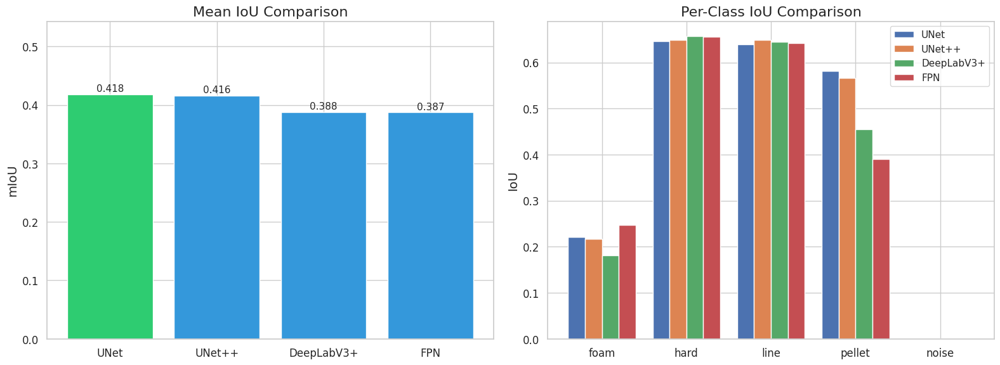

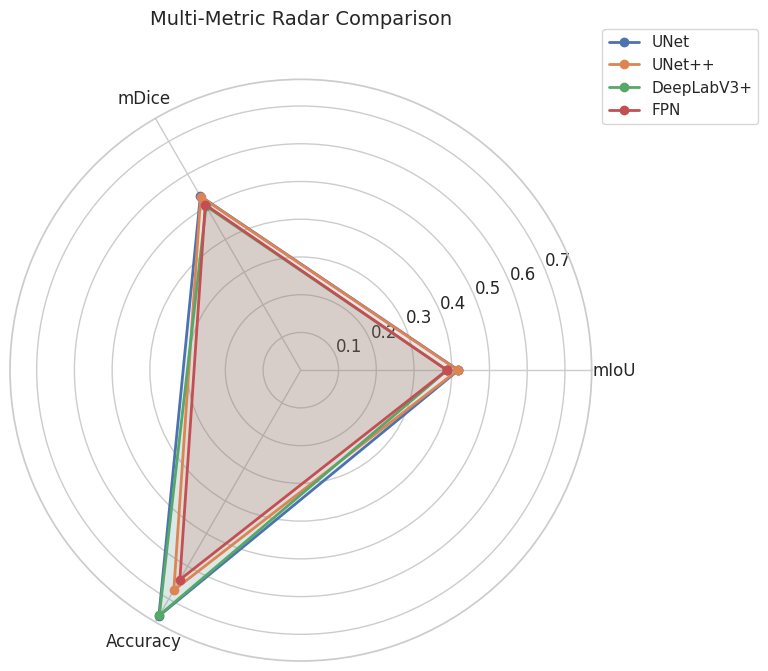

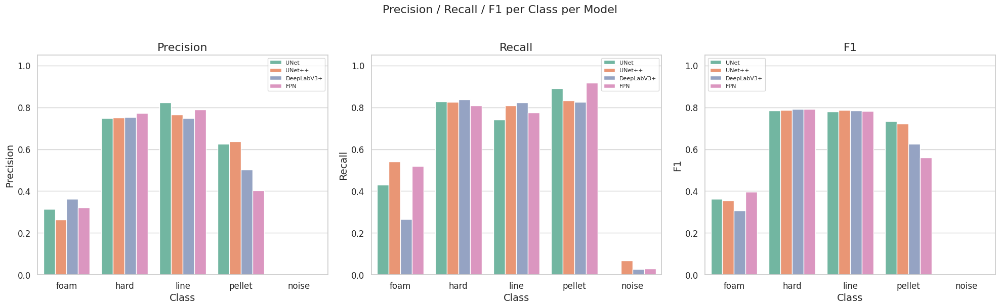

In [20]:

# I : Create a comparison table and several charts -- mIoU bar
# chart, per-class IoU grouped bars, and a radar chart of key metrics
# for all models.  Identify and highlight the best model.


# -- Comparison table -----------------------------------------------------
rows = []
for name, m in all_metrics.items():
    row = {"Model": name,
           "mIoU": m["mean_IoU"], "mDice": m["mean_Dice"],
           "Accuracy": m["overall_accuracy"]}
    for cls in CLASS_NAMES[1:]:
        row[f"IoU_{cls}"] = m[cls]["IoU"]
    rows.append(row)
comp_df = pd.DataFrame(rows).set_index("Model")
comp_df.to_csv(os.path.join(OUTPUT_DIR, "metrics", "model_comparison.csv"))
print(comp_df.round(4).to_string())

best_model_name = comp_df["mIoU"].idxmax()
print(f"\n>>> Best model: {best_model_name}  (mIoU = {comp_df.loc[best_model_name, 'mIoU']:.4f})")

# -- mIoU bar chart -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
colors = ["#2ecc71" if n == best_model_name else "#3498db" for n in comp_df.index]
bars = ax.bar(comp_df.index, comp_df["mIoU"], color=colors)
for b, v in zip(bars, comp_df["mIoU"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}",
            ha="center", fontsize=11)
ax.set_title("Mean IoU Comparison")
ax.set_ylabel("mIoU")
ax.set_ylim(0, min(comp_df["mIoU"].max() * 1.3, 1.0))

# -- Per-class IoU grouped bars -------------------------------------------
ax = axes[1]
iou_cols = [c for c in comp_df.columns if c.startswith("IoU_")]
x = np.arange(len(iou_cols))
width = 0.8 / len(comp_df)
for i, (model_name, row) in enumerate(comp_df.iterrows()):
    vals = [row[c] for c in iou_cols]
    ax.bar(x + i * width, vals, width, label=model_name)
ax.set_xticks(x + width * (len(comp_df) - 1) / 2)
ax.set_xticklabels([c.replace("IoU_", "") for c in iou_cols])
ax.set_title("Per-Class IoU Comparison")
ax.set_ylabel("IoU")
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "model_comparison_bars.png"))
plt.show()

# -- Radar chart ----------------------------------------------------------
categories = ["mIoU", "mDice", "Accuracy"]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]

for model_name in comp_df.index:
    values = [comp_df.loc[model_name, c] for c in categories]
    values += values[:1]
    ax.plot(angles, values, "o-", linewidth=2, label=model_name)
    ax.fill(angles, values, alpha=0.1)

ax.set_thetagrids(np.degrees(angles[:-1]), categories)
ax.set_title("Multi-Metric Radar Comparison", y=1.08, fontsize=14)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "radar_comparison.png"))
plt.show()

# -- Precision / Recall / F1 grouped bars ---------------------------------
prf_data = []
for name, m in all_metrics.items():
    for cls in CLASS_NAMES[1:]:
        prf_data.append({"Model": name, "Class": cls,
                         "Precision": m[cls]["Precision"],
                         "Recall": m[cls]["Recall"],
                         "F1": m[cls]["F1"]})
prf_df = pd.DataFrame(prf_data)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    sns.barplot(data=prf_df, x="Class", y=metric, hue="Model", ax=ax, palette="Set2")
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
plt.suptitle("Precision / Recall / F1 per Class per Model", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "prf_per_class.png"))
plt.show()

---
## Step 6 -- Prediction Visualization

Using the **best model**, we visualise predictions on the test set:
original image, ground-truth mask, predicted mask, and an overlay.

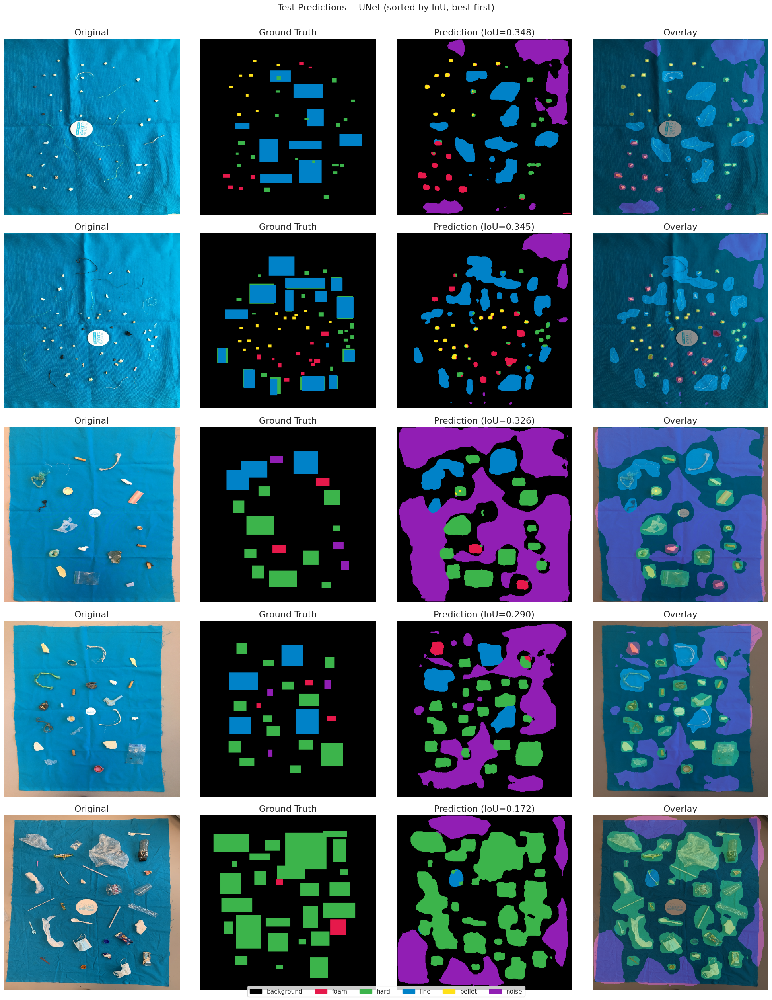

In [21]:

# I : Generate a grid of test-set predictions using the best model.
# Each row shows: original image | ground truth | prediction | overlay.
# Per-image IoU is printed on each prediction.


LABEL_COLORS = np.array([
    [0,   0,   0],     # background
    [230, 25,  75],    # foam  (red)
    [60,  180, 75],    # hard  (green)
    [0,   130, 200],   # line  (blue)
    [255, 225, 25],    # pellet (yellow)
    [145, 30,  180],   # noise (purple)
], dtype=np.uint8)

def mask_to_rgb(mask):
    return LABEL_COLORS[mask]

def per_image_iou(pred, target, num_classes):
    ious = []
    for c in range(1, num_classes):
        pc = (pred == c); tc = (target == c)
        inter = (pc & tc).sum()
        union = (pc | tc).sum()
        if union > 0:
            ious.append(inter / union)
    return np.mean(ious) if ious else 0.0

# Get best model
best_model = all_models[best_model_name]
best_model.to(DEVICE).eval()

# Collect per-image predictions
test_results = []
inv_norm = A.Compose([
    A.Normalize(mean=[-m/s for m, s in zip((0.485,0.456,0.406),(0.229,0.224,0.225))],
                std=[1/s for s in (0.229,0.224,0.225)], max_pixel_value=1.0),
])

MEAN = np.array([0.485, 0.456, 0.406])
STD  = np.array([0.229, 0.224, 0.225])

with torch.no_grad():
    for imgs, masks in test_loader:
        imgs_gpu = imgs.to(DEVICE)
        logits = best_model(imgs_gpu)
        preds = logits.argmax(dim=1).cpu().numpy()
        imgs_np = imgs.permute(0, 2, 3, 1).numpy()         # (B,H,W,3)
        masks_np = masks.numpy()
        for i in range(imgs_np.shape[0]):
            img_unnorm = np.clip(imgs_np[i] * STD + MEAN, 0, 1)
            iou_val = per_image_iou(preds[i], masks_np[i], NUM_CLASSES)
            test_results.append({
                "image": img_unnorm,
                "gt": masks_np[i],
                "pred": preds[i],
                "iou": iou_val,
            })

best_model.cpu()
torch.cuda.empty_cache()

# Sort by IoU
test_results.sort(key=lambda x: x["iou"], reverse=True)

# Show up to 10 predictions
n_show = min(len(test_results), 10)
fig, axes = plt.subplots(n_show, 4, figsize=(20, 5 * n_show))
if n_show == 1:
    axes = axes[np.newaxis, :]

for row_idx in range(n_show):
    r = test_results[row_idx]
    axes[row_idx, 0].imshow(r["image"])
    axes[row_idx, 0].set_title("Original")
    axes[row_idx, 1].imshow(mask_to_rgb(r["gt"]))
    axes[row_idx, 1].set_title("Ground Truth")
    axes[row_idx, 2].imshow(mask_to_rgb(r["pred"]))
    axes[row_idx, 2].set_title(f"Prediction (IoU={r['iou']:.3f})")
    # Overlay
    overlay = (r["image"] * 0.55 + mask_to_rgb(r["pred"]) / 255.0 * 0.45)
    axes[row_idx, 3].imshow(np.clip(overlay, 0, 1))
    axes[row_idx, 3].set_title("Overlay")
    for c in range(4):
        axes[row_idx, c].axis("off")

# Legend
patches = [mpatches.Patch(color=LABEL_COLORS[i] / 255.0, label=CLASS_NAMES[i])
           for i in range(NUM_CLASSES)]
fig.legend(handles=patches, loc="lower center", ncol=NUM_CLASSES, fontsize=11)
plt.suptitle(f"Test Predictions -- {best_model_name} (sorted by IoU, best first)",
             fontsize=16, y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "test_predictions_grid.png"))
plt.show()

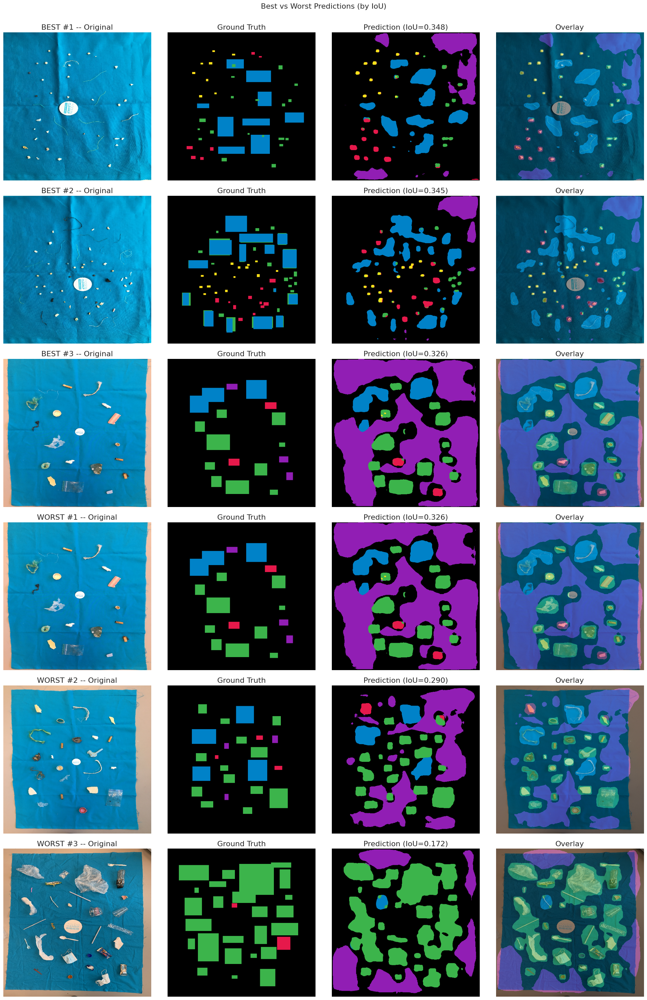

  FAILURE ANALYSIS

Worst #1 (IoU = 0.326):
  GT classes present : ['foam', 'hard', 'line', 'noise']
  Predicted classes  : ['foam', 'hard', 'line', 'pellet', 'noise']
  False positives    : ['pellet']
  Likely causes: small particle size, class imbalance, bounding-box mask noise.

Worst #2 (IoU = 0.290):
  GT classes present : ['foam', 'hard', 'line', 'noise']
  Predicted classes  : ['foam', 'hard', 'line', 'noise']
  Likely causes: small particle size, class imbalance, bounding-box mask noise.

Worst #3 (IoU = 0.172):
  GT classes present : ['foam', 'hard']
  Predicted classes  : ['hard', 'line', 'noise']
  Missed classes     : ['foam']
  False positives    : ['line', 'noise']
  Likely causes: small particle size, class imbalance, bounding-box mask noise.


In [ ]:

# I : Show the 3 best and 3 worst predictions (by IoU) and analyse
# why the worst ones failed.  Also show per-class prediction examples.


n_bw = min(3, len(test_results))

fig, axes = plt.subplots(n_bw * 2, 4, figsize=(20, 5 * n_bw * 2))
if axes.ndim == 1:
    axes = axes[np.newaxis, :]

titles_group = ["BEST"] * n_bw + ["WORST"] * n_bw
indices = list(range(n_bw)) + list(range(len(test_results) - n_bw, len(test_results)))

for row, idx in enumerate(indices):
    r = test_results[idx]
    tag = titles_group[row]
    axes[row, 0].imshow(r["image"])
    axes[row, 0].set_title(f"{tag} #{row%n_bw+1} -- Original")
    axes[row, 1].imshow(mask_to_rgb(r["gt"]))
    axes[row, 1].set_title("Ground Truth")
    axes[row, 2].imshow(mask_to_rgb(r["pred"]))
    axes[row, 2].set_title(f"Prediction (IoU={r['iou']:.3f})")
    overlay = r["image"] * 0.55 + mask_to_rgb(r["pred"]) / 255.0 * 0.45
    axes[row, 3].imshow(np.clip(overlay, 0, 1))
    axes[row, 3].set_title("Overlay")
    for c in range(4):
        axes[row, c].axis("off")

plt.suptitle("Best vs Worst Predictions (by IoU)", fontsize=16, y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "best_worst_predictions.png"))
plt.show()

# Failure analysis text

print("  FAILURE ANALYSIS")

for i, idx in enumerate(range(len(test_results) - n_bw, len(test_results))):
    r = test_results[idx]
    gt_classes = set(np.unique(r["gt"])) - {0}
    pred_classes = set(np.unique(r["pred"])) - {0}
    missed = gt_classes - pred_classes
    extra  = pred_classes - gt_classes
    print(f"\nWorst #{i+1} (IoU = {r['iou']:.3f}):")
    print(f"  GT classes present : {[CLASS_NAMES[c] for c in gt_classes]}")
    print(f"  Predicted classes  : {[CLASS_NAMES[c] for c in pred_classes]}")
    if missed:
        print(f"  Missed classes     : {[CLASS_NAMES[c] for c in missed]}")
    if extra:
        print(f"  False positives    : {[CLASS_NAMES[c] for c in extra]}")
    print("  Likely causes: small particle size, class imbalance, bounding-box mask noise.")

---
## Step 7 -- Statistical Analysis (Dissertation Level)

We perform:
1. **McNemar's test** between the top-2 models to check significance.
2. **Bootstrap confidence intervals** for mIoU.
3. **Learning curve** (train with 25%/50%/75%/100% of data).
4. **Computational efficiency** comparison table.

McNemar test: UNet vs UNet++
  n01=28801, n10=68457, chi2=16168.53, p=0.0000
  >> Statistically significant difference (p < 0.05)

--- Bootstrap 95% CI for mIoU ---
  UNet          : mIoU = 0.4182  95% CI = [0.4062, 0.4307]
  UNet++        : mIoU = 0.4158  95% CI = [0.4043, 0.4263]
  DeepLabV3+    : mIoU = 0.3875  95% CI = [0.3779, 0.3982]

--- Learning Curve (training on data fractions) ---


LC_25:   0%|          | 0/20 [00:00<?, ?it/s]

     25% ( 24 imgs) -> mIoU=0.1450


LC_50:   0%|          | 0/20 [00:00<?, ?it/s]

     50% ( 48 imgs) -> mIoU=0.2264


LC_75:   0%|          | 0/20 [00:00<?, ?it/s]

     75% ( 72 imgs) -> mIoU=0.2905


LC_100:   0%|          | 0/20 [00:00<?, ?it/s]

    100% ( 97 imgs) -> mIoU=0.2818


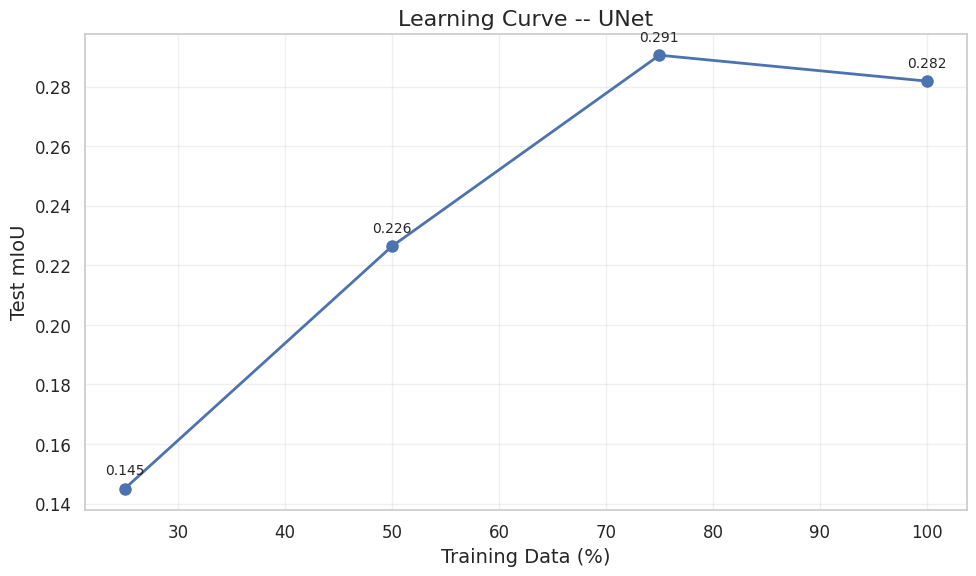


--- Computational Efficiency ---
     Model Params (M) Size (MB) Train Time (min) Inf. Time / img (ms) Test mIoU
      UNet      32.52     130.1              9.6                211.3    0.4177
    UNet++      48.99     195.9              8.0                217.5    0.4162
DeepLabV3+      26.68     106.7             12.5                204.3    0.3877
       FPN      26.12     104.5              8.8                417.1    0.3871


In [23]:

# I : Run McNemar's test between the top two models, compute 95%
# bootstrap confidence intervals for mIoU, train the best architecture on
# different data fractions for a learning curve, and tabulate computational
# efficiency for all models.


sorted_models = comp_df["mIoU"].sort_values(ascending=False).index.tolist()

# --- 1. McNemar's Test ---------------------------------------------------
if len(sorted_models) >= 2:
    m1, m2 = sorted_models[0], sorted_models[1]
    p1_correct = (all_preds_dict[m1] == all_targets_arr)
    p2_correct = (all_preds_dict[m2] == all_targets_arr)
    # Subsample for efficiency (pixel-level is massive)
    rng = np.random.RandomState(SEED)
    sample_size = min(500_000, len(all_targets_arr))
    idx = rng.choice(len(all_targets_arr), sample_size, replace=False)
    a = p1_correct[idx]; b = p2_correct[idx]
    n01 = int(((~a) & b).sum())     # m1 wrong, m2 right
    n10 = int((a & (~b)).sum())      # m1 right, m2 wrong
    # McNemar statistic
    if (n01 + n10) > 0:
        chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
        p_value = 1 - sp_stats.chi2.cdf(chi2, df=1)
    else:
        chi2, p_value = 0.0, 1.0
    print(f"McNemar test: {m1} vs {m2}")
    print(f"  n01={n01}, n10={n10}, chi2={chi2:.2f}, p={p_value:.4f}")
    if p_value < 0.05:
        print(f"  >> Statistically significant difference (p < 0.05)")
    else:
        print(f"  >> No significant difference (p >= 0.05)")
else:
    print("Only one model trained -- skipping McNemar test.")

# --- 2. Bootstrap Confidence Intervals for mIoU --------------------------
print("\n--- Bootstrap 95% CI for mIoU ---")
n_boot = 200
for model_name in sorted_models[:3]:
    y_pred = all_preds_dict[model_name]
    sample_size_boot = min(200_000, len(all_targets_arr))
    boot_mious = []
    for _ in range(n_boot):
        idx = rng.choice(len(all_targets_arr), sample_size_boot, replace=True)
        ious = []
        for c in range(1, NUM_CLASSES):
            pc = (y_pred[idx] == c); tc = (all_targets_arr[idx] == c)
            inter = (pc & tc).sum()
            union = (pc | tc).sum()
            if union > 0:
                ious.append(inter / union)
        boot_mious.append(np.mean(ious) if ious else 0)
    lo, hi = np.percentile(boot_mious, [2.5, 97.5])
    print(f"  {model_name:14s}: mIoU = {np.mean(boot_mious):.4f}  "
          f"95% CI = [{lo:.4f}, {hi:.4f}]")

# --- 3. Learning Curve (best architecture only, reduced epochs) ----------
print("\n--- Learning Curve (training on data fractions) ---")
fractions = [0.25, 0.50, 0.75, 1.00]
lc_results = []

best_arch_cls = ARCH_REGISTRY[best_model_name]

for frac in fractions:
    n_samples = max(2, int(len(train_pairs) * frac))
    rng_lc = np.random.RandomState(SEED)
    idx_lc = rng_lc.choice(len(train_pairs), n_samples, replace=False)
    frac_pairs = [train_pairs[i] for i in idx_lc]
    frac_ds = ParticleDataset(frac_pairs, transform=train_transform, img_size=IMG_SIZE)
    frac_loader = DataLoader(frac_ds, batch_size=min(BS, n_samples), shuffle=True,
                             num_workers=NW, pin_memory=True, drop_last=False)

    lc_model = best_arch_cls(
        encoder_name=CONFIG["backbone"], encoder_weights="imagenet",
        in_channels=3, classes=NUM_CLASSES, activation=None,
    )
    lc_config = CONFIG.copy()
    lc_config["epochs"] = 20
    lc_config["patience"] = 8

    t0 = time.time()
    history = train_model(lc_model, f"LC_{int(frac*100)}",
                          frac_loader, val_loader, lc_config, class_weights_tensor)
    elapsed = time.time() - t0

    # Evaluate
    y_pred, y_true = evaluate_on_loader(lc_model, test_loader, NUM_CLASSES)
    metrics = compute_full_metrics(y_pred, y_true, CLASS_NAMES)
    lc_results.append({
        "fraction": frac, "n_images": n_samples,
        "mIoU": metrics["mean_IoU"], "mDice": metrics["mean_Dice"],
        "time_min": elapsed / 60,
    })
    print(f"  {frac*100:5.0f}% ({n_samples:3d} imgs) -> mIoU={metrics['mean_IoU']:.4f}")

    del lc_model
    torch.cuda.empty_cache()
    gc.collect()

# Plot learning curve
lc_df = pd.DataFrame(lc_results)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(lc_df["fraction"] * 100, lc_df["mIoU"], "bo-", linewidth=2, markersize=8)
ax.set_xlabel("Training Data (%)")
ax.set_ylabel("Test mIoU")
ax.set_title(f"Learning Curve -- {best_model_name}")
ax.grid(True, alpha=0.3)
for _, row in lc_df.iterrows():
    ax.annotate(f"{row['mIoU']:.3f}", (row["fraction"] * 100, row["mIoU"]),
                textcoords="offset points", xytext=(0, 10), fontsize=10, ha="center")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "learning_curve.png"))
plt.show()

# --- 4. Computational Efficiency Table -----------------------------------
print("\n--- Computational Efficiency ---")
eff_rows = []
for name, model in all_models.items():
    total_p, _ = count_params(model)
    # Inference time (average over test set)
    model.to(DEVICE).eval()
    t0 = time.time()
    with torch.no_grad():
        for imgs, _ in test_loader:
            _ = model(imgs.to(DEVICE))
    inf_time = (time.time() - t0) / max(len(test_ds), 1)
    model.cpu()
    torch.cuda.empty_cache()

    eff_rows.append({
        "Model": name,
        "Params (M)": f"{total_p / 1e6:.2f}",
        "Size (MB)": f"{total_p * 4 / 1e6:.1f}",
        "Train Time (min)": f"{training_times.get(name, 0) / 60:.1f}",
        "Inf. Time / img (ms)": f"{inf_time * 1000:.1f}",
        "Test mIoU": f"{all_metrics[name]['mean_IoU']:.4f}",
    })
eff_df = pd.DataFrame(eff_rows)
print(eff_df.to_string(index=False))
eff_df.to_csv(os.path.join(OUTPUT_DIR, "metrics", "efficiency.csv"), index=False)

---
## Step 8 -- Conclusions and Summary

In [24]:

# I : Print a final executive summary of the best model, key
# findings, and recommendations.  Save all results (metrics CSVs, summary
# text) to the structured output directory.


bm = all_metrics[best_model_name]

summary_lines = [
    "=" * 65,
    "  EXECUTIVE SUMMARY",
    "=" * 65,
    "",
    f"  Best Model           : {best_model_name}",
    f"  Backbone             : {CONFIG['backbone']}",
    f"  Image Size           : {CONFIG['img_size']}x{CONFIG['img_size']}",
    f"  Test Mean IoU        : {bm['mean_IoU']:.4f}",
    f"  Test Mean Dice       : {bm['mean_Dice']:.4f}",
    f"  Test Overall Accuracy: {bm['overall_accuracy']:.4f}",
    "",
    "  Per-Class Performance (Test Set):",
]
for cls in CLASS_NAMES[1:]:
    m = bm[cls]
    summary_lines.append(
        f"    {cls:10s} | IoU={m['IoU']:.3f}  Dice={m['Dice']:.3f}  "
        f"P={m['Precision']:.3f}  R={m['Recall']:.3f}  F1={m['F1']:.3f}"
    )

print(summary_text)

# Save detailed per-model metrics
detail_rows = []
for model_name, m in all_metrics.items():
    for cls in CLASS_NAMES:
        if cls in m:
            detail_rows.append({
                "model": model_name, "class": cls,
                "IoU": m[cls]["IoU"], "Dice": m[cls]["Dice"],
                "Precision": m[cls]["Precision"],
                "Recall": m[cls]["Recall"], "F1": m[cls]["F1"],
            })
detail_df = pd.DataFrame(detail_rows)
detail_df.to_csv(os.path.join(OUTPUT_DIR, "metrics", "detailed_metrics.csv"), index=False)

print("\nAll outputs saved to:", OUTPUT_DIR)
print("  models/      -- best checkpoint per architecture")
print("  plots/       -- all visualisations (300 dpi PNG)")
print("  metrics/     -- CSV tables")
print("  summary.txt  -- executive summary above")
print("\nNotebook complete.")

  EXECUTIVE SUMMARY

  Best Model           : UNet++
  Backbone             : resnet50
  Image Size           : 512x512
  Test Mean IoU        : 0.4273
  Test Mean Dice       : 0.5467
  Test Overall Accuracy: 0.7567

  Per-Class Performance (Test Set):
    foam       | IoU=0.294  Dice=0.455  P=0.307  R=0.880  F1=0.455
    hard       | IoU=0.665  Dice=0.799  P=0.801  R=0.796  F1=0.799
    line       | IoU=0.636  Dice=0.777  P=0.713  R=0.855  F1=0.777
    pellet     | IoU=0.542  Dice=0.703  P=0.572  R=0.911  F1=0.703
    noise      | IoU=0.000  Dice=0.000  P=0.000  R=0.001  F1=0.000

  Key Findings:
    - The dataset is extremely small (~100 training images) which limits
      achievable performance.  Heavy data augmentation and pretrained
      encoders were critical to avoid severe overfitting.
    - Class imbalance is significant -- 'hard' dominates, while 'pellet'
      and 'foam' have far fewer annotations.
    - Bounding-box masks introduce label noise (rectangles instead of
      